# Institutions and development: AJR (2001)
Baseline 2SLS on the 64-country sample used in metricsAI Chapter 13.
Instrument: log settler mortality (`logem4`); endogenous regressor: protection against expropriation (`avexpr`); outcome: log GDP per capita in 1995 (`logpgp95`). No additional controls.

The first-stage graphic is generated below with Matplotlib, using country labels in the paper's style. The IV estimate uses PyFixest with HC1 standard errors.

Sources: [AJR data archive](https://economics.mit.edu/people/faculty/daron-acemoglu/data-archive), [PyFixest IV documentation](https://pyfixest.org/tutorials/formula-syntax.html).
Causal interpretation requires the instrument's relevance and exclusion assumptions.


In [ ]:
%pip -q install pyfixest==0.60.0

In [1]:
import pandas as pd
import pyfixest as pf
import matplotlib.pyplot as plt

df = pd.read_stata("https://raw.githubusercontent.com/quarcs-lab/metricsai/main/data/AED_INSTITUTIONS.DTA")
df = df.dropna(subset=["logpgp95", "avexpr", "logem4"])
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#334155", "xtick.color": "#475569",
    "ytick.color": "#475569", "axes.edgecolor": "#94a3b8",
    "figure.facecolor": "white", "axes.facecolor": "white",
})

In [2]:
iv = pf.feols(
    "logpgp95 ~ 1 | avexpr ~ logem4",
    data=df, vcov="HC1"
)
iv.summary()

###

Estimation:  IV
Dep. var.: logpgp95
sample: None = all
Inference:  HC1
Observations:  64

| Coefficient   |   Estimate |   Std. Error |   t value |   Pr(>|t|) |   2.5% |   97.5% |
|:--------------|-----------:|-------------:|----------:|-----------:|-------:|--------:|
| Intercept     |      1.910 |        1.193 |     1.601 |      0.114 | -0.475 |   4.294 |
| avexpr        |      0.944 |        0.179 |     5.278 |      0.000 |  0.587 |   1.302 |
---



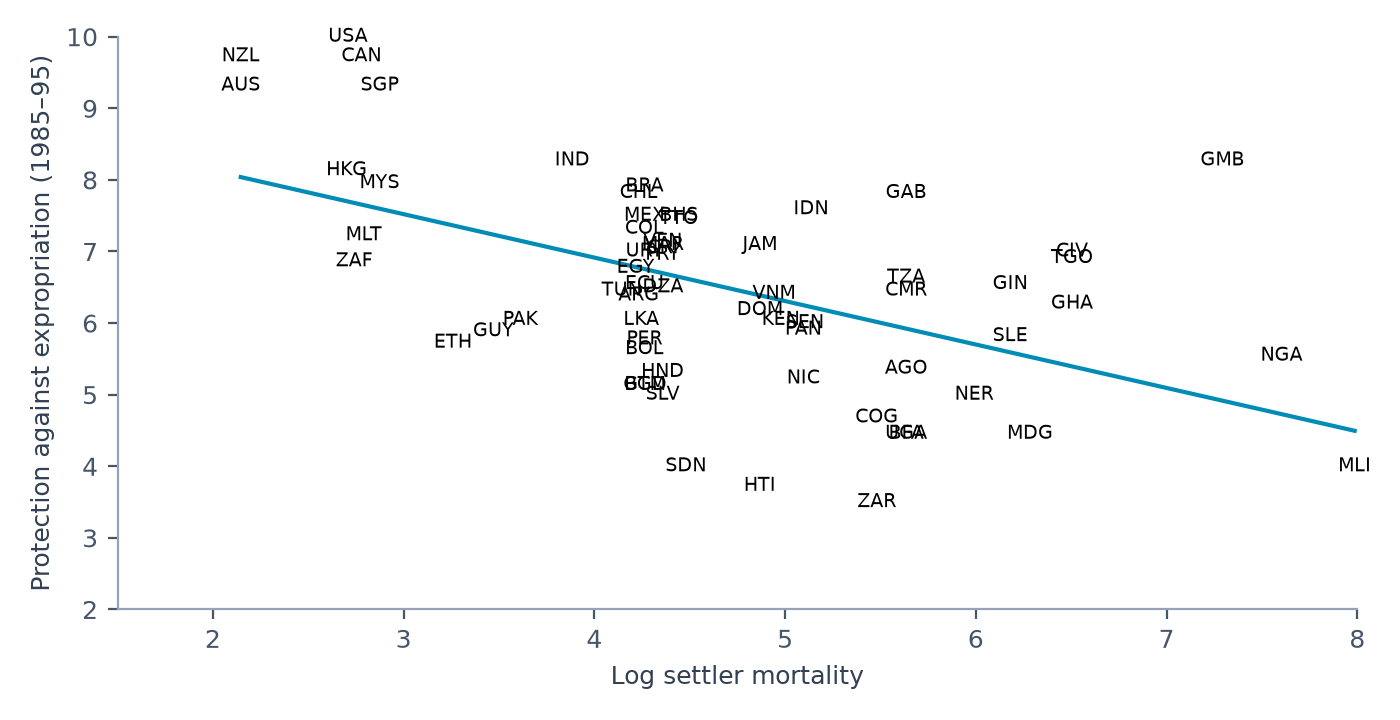

In [3]:
first = pf.feols("avexpr ~ logem4", data=df)
fig, ax = plt.subplots(figsize=(7, 3.6))
for r in df.itertuples():
    ax.text(r.logem4, r.avexpr, r.shortnam,
            fontsize=7, ha="center", va="center")
ordered = df.sort_values("logem4")
ax.plot(ordered.logem4, first.predict(ordered), color="#008CB7")
ax.set(xlim=(1.5, 8), ylim=(2, 10), xlabel="Log settler mortality",
       ylabel="Protection against expropriation (1985–95)")
fig.tight_layout()
plt.show()